# Lab 12-08 · Op-Amp Internals

Companion to [chapter 12-08](../../chapters/12-08-op-amp-internals.md). Four parts: a two-stage op-amp's gain, bandwidth and margin from its bias design; its large-signal step response and slew rates; a folded cascode at similar power; and the transconductance of a complementary rail-to-rail input stage. Run the cells in order.

In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.optimize import brentq, fsolve

TP = 2 * math.pi


def two_stage(gm1, R1, C1, gm6, R2, CL, Cc):
    def A(f):
        s = 1j * TP * f
        Y = np.array([[1 / R1 + s * (C1 + Cc), -s * Cc], [gm6 - s * Cc, 1 / R2 + s * (CL + Cc)]])
        return np.linalg.solve(Y, np.array([-gm1, 0]))[1]
    return A


def margins(A, lo=1.0, hi=1e11):
    fc = brentq(lambda f: abs(A(f)) - 1, lo, hi, xtol=1e-6, rtol=1e-15)
    fs = np.geomspace(lo, fc, 3000)
    return fc, 180 + np.degrees(np.unwrap(np.angle([A(f) for f in fs])))[-1]


def design(Iss=20e-6, I7=100e-6, Vov=0.2, lam=0.1, CL=5e-12, C1=0.2e-12):
    gm1, gm6 = Iss / Vov, 2 * I7 / Vov
    R1, R2 = 1 / (lam * Iss / 2) / 2, 1 / (lam * I7) / 2
    Cc = 0.22 * CL
    A = two_stage(gm1, R1, C1, gm6, R2, CL, Cc)
    fc, pm = margins(A)
    return dict(A0=abs(A(1e-3)), GBW=gm1 / (TP * Cc), fc=fc, pm=pm)

## Part 1 · Gain, bandwidth and margin from the bias design

Example 12-08.1's design, then the effect of λ (channel length) and the load.

In [2]:
for kw in [{}, {'lam': 0.05}, {'CL': 10e-12}, {'Vov': 0.15}]:
    d = design(**kw)
    print(f"{str(kw):18s} A0 = {d['A0']:8.0f} ({20 * math.log10(d['A0']):5.2f} dB), GBW = {d['GBW'] / 1e6:6.2f} MHz, "
          f"crossover {d['fc'] / 1e6:6.2f} MHz, PM = {d['pm']:5.2f} deg")
d = design(CL=10e-12)
gm1, gm6 = 20e-6 / 0.2, 2 * 100e-6 / 0.2
fc, pm = margins(two_stage(gm1, 500e3, 0.2e-12, gm6, 50e3, 10e-12, 1.1e-12))
print(f"C_L = 10 pF with C_c kept at 1.1 pF: PM = {pm:.2f} deg at {fc / 1e6:.2f} MHz")

{}                 A0 =     2500 (67.96 dB), GBW =  14.47 MHz, crossover  12.70 MHz, PM = 59.78 deg
{'lam': 0.05}      A0 =    10000 (80.00 dB), GBW =  14.47 MHz, crossover  12.85 MHz, PM = 59.07 deg
{'CL': 1e-11}      A0 =     2500 (67.96 dB), GBW =   7.23 MHz, crossover   6.45 MHz, PM = 61.39 deg
{'Vov': 0.15}      A0 =     4444 (72.96 dB), GBW =  19.29 MHz, crossover  17.03 MHz, PM = 59.42 deg
C_L = 10 pF with C_c kept at 1.1 pF: PM = 47.41 deg at 10.91 MHz


## Part 2 · Large-signal step response and slew (the chapter's guided exercise)

A unity-gain follower with a square-law NMOS input pair (its output current saturates at $\pm I_{SS}$) and a square-law PMOS second stage M6 that sources current into the output against the NMOS sink $I_7$, and cuts off when its gate (node 1) rises. **Predict first:** with $I_7$ doubled to 200 µA (M6 resized to keep 0.2 V overdrive), which edge speeds up?

I7 = 100 uA, rising: max slope 17.74 V/us


I7 = 100 uA, falling: max slope 16.20 V/us
I7 = 200 uA, rising: max slope 17.76 V/us


I7 = 200 uA, falling: max slope 17.47 V/us


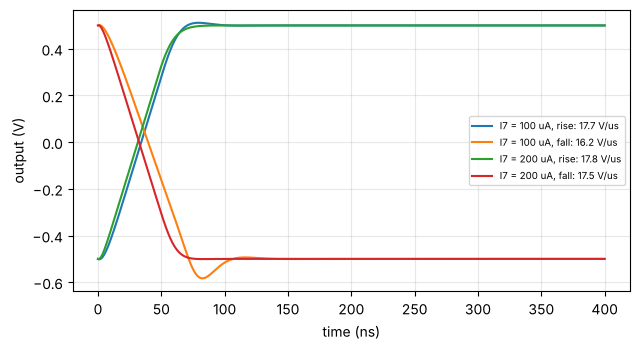

In [3]:
def follower(I7, Iss=20e-6, Vov=0.2, lam=0.1, Cc=1.1e-12, CL=5e-12, C1=0.2e-12, v0=-0.5, vs=0.5):
    k1, k6 = 2 * (Iss / 2) / Vov ** 2, 2 * I7 / Vov ** 2
    R1, R2 = 1 / (lam * Iss / 2) / 2, 1 / (lam * I7) / 2
    lim = math.sqrt(2 * Iss / k1)
    i1 = lambda x: math.copysign(Iss, x) if abs(x) >= lim else (k1 / 2) * x * math.sqrt(4 * Iss / k1 - x * x)
    i6 = lambda v1: (k6 / 2) * (Vov - v1) ** 2 - I7 if v1 < Vov else -I7   # PMOS: net current into the output
    Ci = np.linalg.inv(np.array([[C1 + Cc, -Cc], [-Cc, CL + Cc]]))
    x0 = fsolve(lambda x: [-i1(v0 - x[1]) - x[0] / R1, i6(x[0]) - x[1] / R2], [0.0, v0], xtol=1e-12)
    sol = solve_ivp(lambda t, x: Ci @ np.array([-i1(vs - x[1]) - x[0] / R1, i6(x[0]) - x[1] / R2]),
                    (0, 0.4e-6), x0, method='Radau', max_step=1e-9, rtol=1e-9, atol=1e-12)
    return sol.t, sol.y[1]
fig, ax = plt.subplots(figsize=(6.5, 3.6))
for I7 in (100e-6, 200e-6):
    for v0, vs in ((-0.5, 0.5), (0.5, -0.5)):
        t, vo = follower(I7, v0=v0, vs=vs)
        sr = np.max(np.abs(np.gradient(vo, t))) / 1e6
        ax.plot(t * 1e9, vo, label=f'I7 = {I7 * 1e6:.0f} uA, {"rise" if vs > 0 else "fall"}: {sr:.1f} V/us')
        print(f"I7 = {I7 * 1e6:.0f} uA, {'rising' if vs > 0 else 'falling'}: max slope {sr:.2f} V/us")
ax.set_xlabel('time (ns)'); ax.set_ylabel('output (V)'); ax.grid(True, alpha=0.3); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

## Part 3 · A folded cascode at similar power

Example 12-08.4's folded cascode, solved transistor by transistor (small signal): gain, crossover and margin against load capacitance. Note that a larger load *raises* its phase margin.

In [4]:
def folded(CL, Cf=0.5e-12, gm=0.5e-3, lam=0.1):
    ro50, ro100 = 1 / (lam * 50e-6), 1 / (lam * 100e-6)
    def A(f):
        s = 1j * TP * f
        Rf = 1 / (1 / ro50 + 1 / ro100)
        # nodes: fold, out, nb (NMOS cascode source)
        Y = np.array([[1 / Rf + s * Cf + gm + 1 / ro50, -1 / ro50, 0],
                      [-gm - 1 / ro50, 1 / ro50 + 1 / ro50 + s * CL, -1 / ro50 - gm],
                      [0, -1 / ro50, 1 / ro50 + gm + 1 / ro50]])
        return -np.linalg.solve(Y, np.array([-gm, 0, 0]))[1]
    return A
for CL in (1e-12, 2e-12, 5e-12):
    A = folded(CL)
    fc, pm = margins(A)
    print(f"C_L = {CL * 1e12:.0f} pF: A0 = {abs(A(1e-2)):.0f}, crossover {fc / 1e6:.2f} MHz, PM = {pm:.2f} deg")

C_L = 1 pF: A0 = 2513, crossover 70.78 MHz, PM = 66.97 deg
C_L = 2 pF: A0 = 2513, crossover 37.60 MHz, PM = 77.25 deg


C_L = 5 pF: A0 = 2513, crossover 15.38 MHz, PM = 84.72 deg


## Part 4 · A complementary input stage

$g_m$ against input common mode on a 2.5 V supply ($V_{TH}$ = 0.5 V, 0.2 V overdrives), with constant tail currents and with a constant-$g_m$ rule that quarters each pair's current where both conduct. Each pair is modelled as fully on or off at its limit (real pairs fade over about 100 mV).

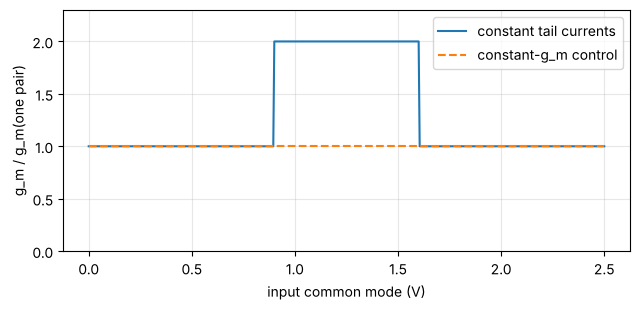

In [5]:
vcm = np.linspace(0, 2.5, 501)
n_on = vcm >= 0.9; p_on = vcm <= 1.6
g_const = n_on * 1.0 + p_on * 1.0
both = n_on & p_on
g_cgm = np.where(both, 2 * math.sqrt(0.25), g_const)   # sqrt(I/4) relative to sqrt(I) for each pair
fig, ax = plt.subplots(figsize=(6.5, 3.2))
ax.plot(vcm, g_const, label='constant tail currents'); ax.plot(vcm, g_cgm, '--', label='constant-g_m control')
ax.set_xlabel('input common mode (V)'); ax.set_ylabel('g_m / g_m(one pair)'); ax.set_ylim(0, 2.3); ax.grid(True, alpha=0.3); ax.legend()
plt.tight_layout(); plt.show()